# Research Assignment: Modularity on the Karate Club Graph
**Course:** DSC212 – Graph Theory Module

**Goal:** implement the spectral modularity method (Newman, 2006) from scratch on Zachary's Karate Club network, extend it to many communities by recursive bisection, visualise every split, and study how node-level metrics change as the graph is divided.

**SUMMARY**
1. Build the adjacency matrix `A` and modularity matrix `B = A - k kᵀ / 2m`
2. Two-way split using the sign of the leading eigenvector of `B`
3. Recursive bisection (stop when the leading eigenvalue of every block is ≤ 0)
4. Colour the graph after every iteration (fixed layout)
5. Compute degree / betweenness / closeness / clustering after every iteration
6. Plot how each metric evolves.

**Libraries:** `numpy`, `matplotlib`, `networkx` only.

# 1. Setup
Zachary's Karate Club graph (34 nodes, 78 edges) is loaded from NetworkX. A fixed random seed is used for the layout so that every picture in this notebook has the nodes in the same place. Figures are also saved in an `assets/` folder for the GitHub repository.

nodes: 34 | edges: 78


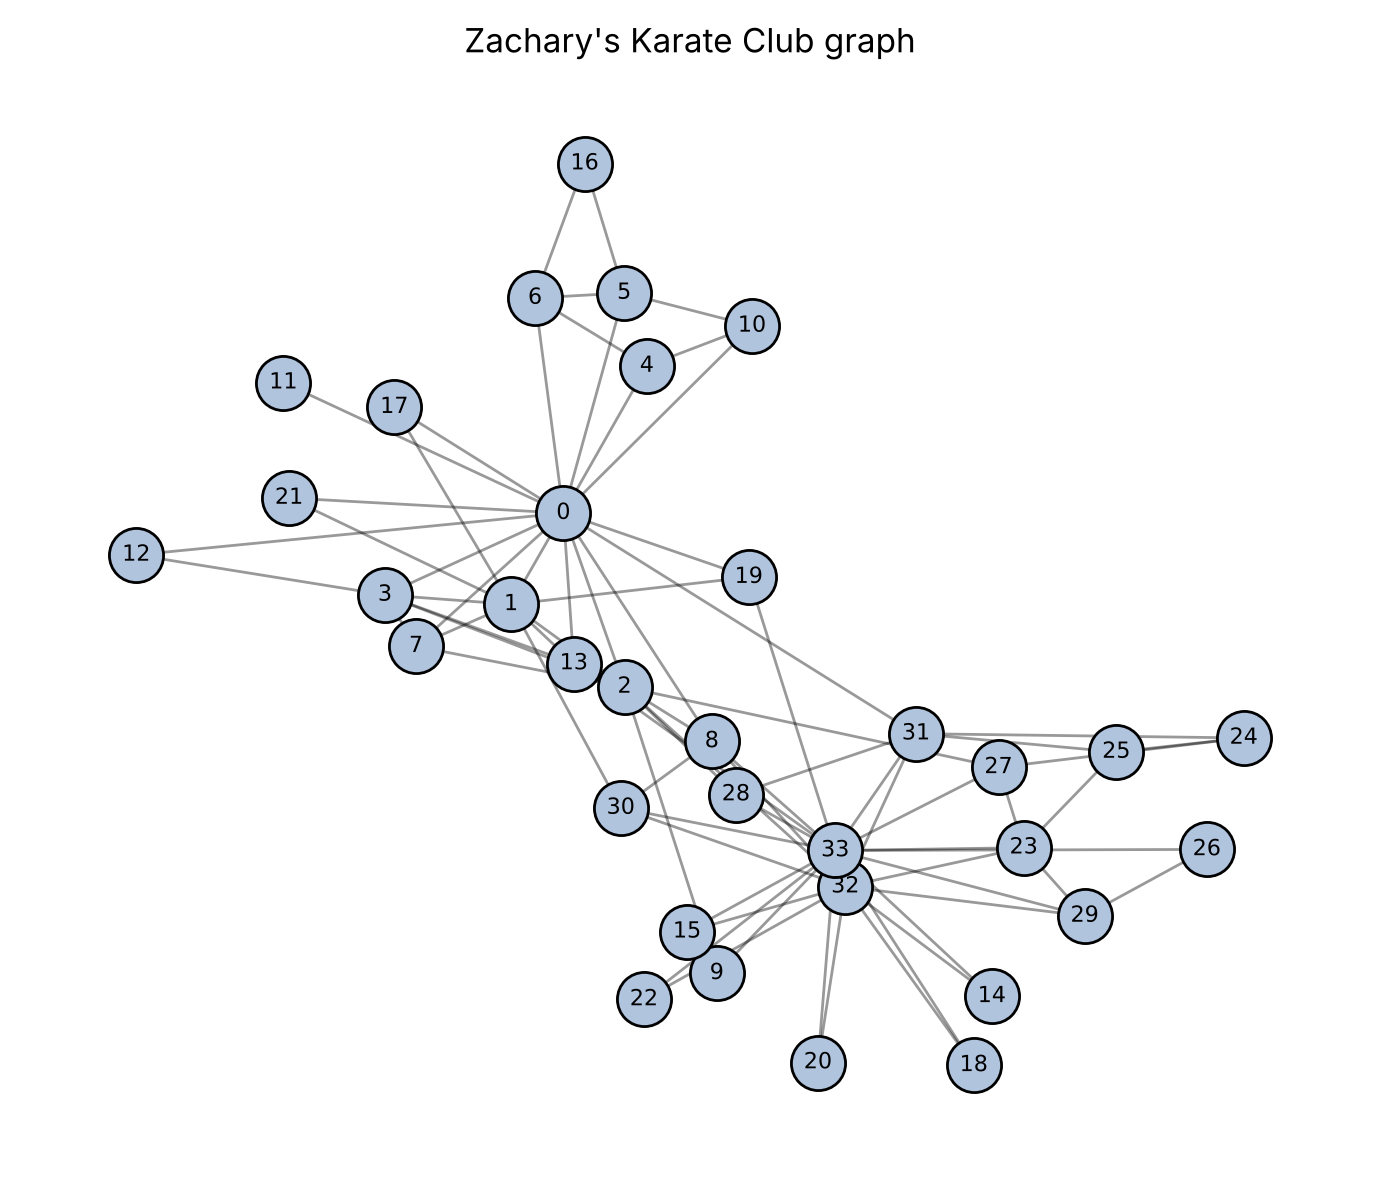

In [ ]:
import os
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

os.makedirs("assets", exist_ok=True)           # figures are saved here

G = nx.karate_club_graph()
n = G.number_of_nodes()
print("nodes:", n, "| edges:", G.number_of_edges())

pos = nx.spring_layout(G, seed=42)             # fixed layout reused for every plot

plt.figure(figsize=(7, 6))
nx.draw_networkx_edges(G, pos, alpha=0.4)
nx.draw_networkx_nodes(G, pos, node_color="lightsteelblue", node_size=380, edgecolors="black")
nx.draw_networkx_labels(G, pos, font_size=8)
plt.title("Zachary's Karate Club graph")
plt.axis("off"); plt.tight_layout()
plt.savefig("assets/00_karate_graph.png", dpi=150)
plt.show()

# 2. Adjacency matrix and modularity matrix
* `A[i][j] = 1` if members *i* and *j* interact, else `0`. NetworkX's karate graph carries a `weight` attribute, so `weight=None` is passed to get the plain 0/1 matrix.
* `k = A.sum(axis=1)` is the degree vector and `m = Σkᵢ / 2` is the number of edges.
* **Modularity matrix:** `B = A − k kᵀ / (2m)`. The second term is the expected number of edges between *i* and *j* under the degree-preserving null model, so `B[i][j] > 0` means *i* and *j* are linked more than chance predicts.

Checks from the handout: `B` is real symmetric (Proposition 1), and `B·1 = 0` (Proposition 2) so every row of `B` sums to 0 and `0` is always an eigenvalue of the global `B`.

In [ ]:
A = nx.to_numpy_array(G, nodelist=range(n), weight=None)
k = A.sum(axis=1)
m = A.sum() / 2
B = A - np.outer(k, k) / (2 * m)

print("A shape:", A.shape, "| m =", m)
print("B symmetric?             ", np.allclose(B, B.T))
print("rows of B sum to 0?      ", np.allclose(B.sum(axis=1), 0))
print("B @ 1 == 0 ?             ", np.allclose(B @ np.ones(n), 0))
print("all eigenvalues real?    ", np.isrealobj(np.linalg.eigvalsh(B)))
print("smallest |eigenvalue|:   ", np.abs(np.linalg.eigvalsh(B)).min().round(12), "(the guaranteed zero eigenvalue)")

A shape: (34, 34) | m = 78.0
B symmetric?              True
rows of B sum to 0?       True
B @ 1 == 0 ?              True
all eigenvalues real?     True
smallest |eigenvalue|:    0.0 (the guaranteed zero eigenvalue)


# 3. Two-way split (spectral bipartition)
A division is encoded by `s ∈ {+1, −1}ⁿ` and scored by the modularity

`Q = sᵀ B s / (4m)`.

Checking all `2ⁿ` vectors is impossible, so `s` is **relaxed** to any real vector with `‖s‖₂ = 1`:  `max sᵀBs`. By Rayleigh–Ritz, `sᵀBs = Σ αᵢ² λᵢ ≤ λ₁`, with equality at the leading eigenvector `u₁`. The hard partition is recovered by `sᵢ = +1 if (u₁)ᵢ > 0 else −1`.

`np.linalg.eigh` is used because `B` is symmetric; it returns eigenvalues in **ascending** order, so the leading pair is the last one.

*Note: flipping the signs of `s` leaves `Q` unchanged (the two minus signs cancel), so the labels "group 1/2" are arbitrary.*

In [ ]:
values, vectors = np.linalg.eigh(B)
lam1, u1 = values[-1], vectors[:, -1]          # leading eigenpair
s = np.where(u1 > 0, 1, -1)

Q_two = s @ B @ s / (4 * m)
set1 = set(np.where(s == 1)[0].tolist())
set2 = set(range(n)) - set1

print("largest eigenvalue:", round(lam1, 4))
print("group sizes:", len(set1), "and", len(set2))
print("Q (two groups):", round(Q_two, 4))

largest eigenvalue: 4.9771
group sizes: 16 and 18
Q (two groups): 0.3715


### Comparison with the real split
Zachary recorded which faction each member joined (`club` = "Mr. Hi" or "Officer"). Nodes where our bipartition disagrees with the real split are listed below. Because group labels are arbitrary, the comparison is made against whichever of our two groups overlaps more with Mr. Hi's faction.

Mr. Hi faction size (true / ours): 17 / 16
misclassified nodes: [8]
accuracy: 97.1%


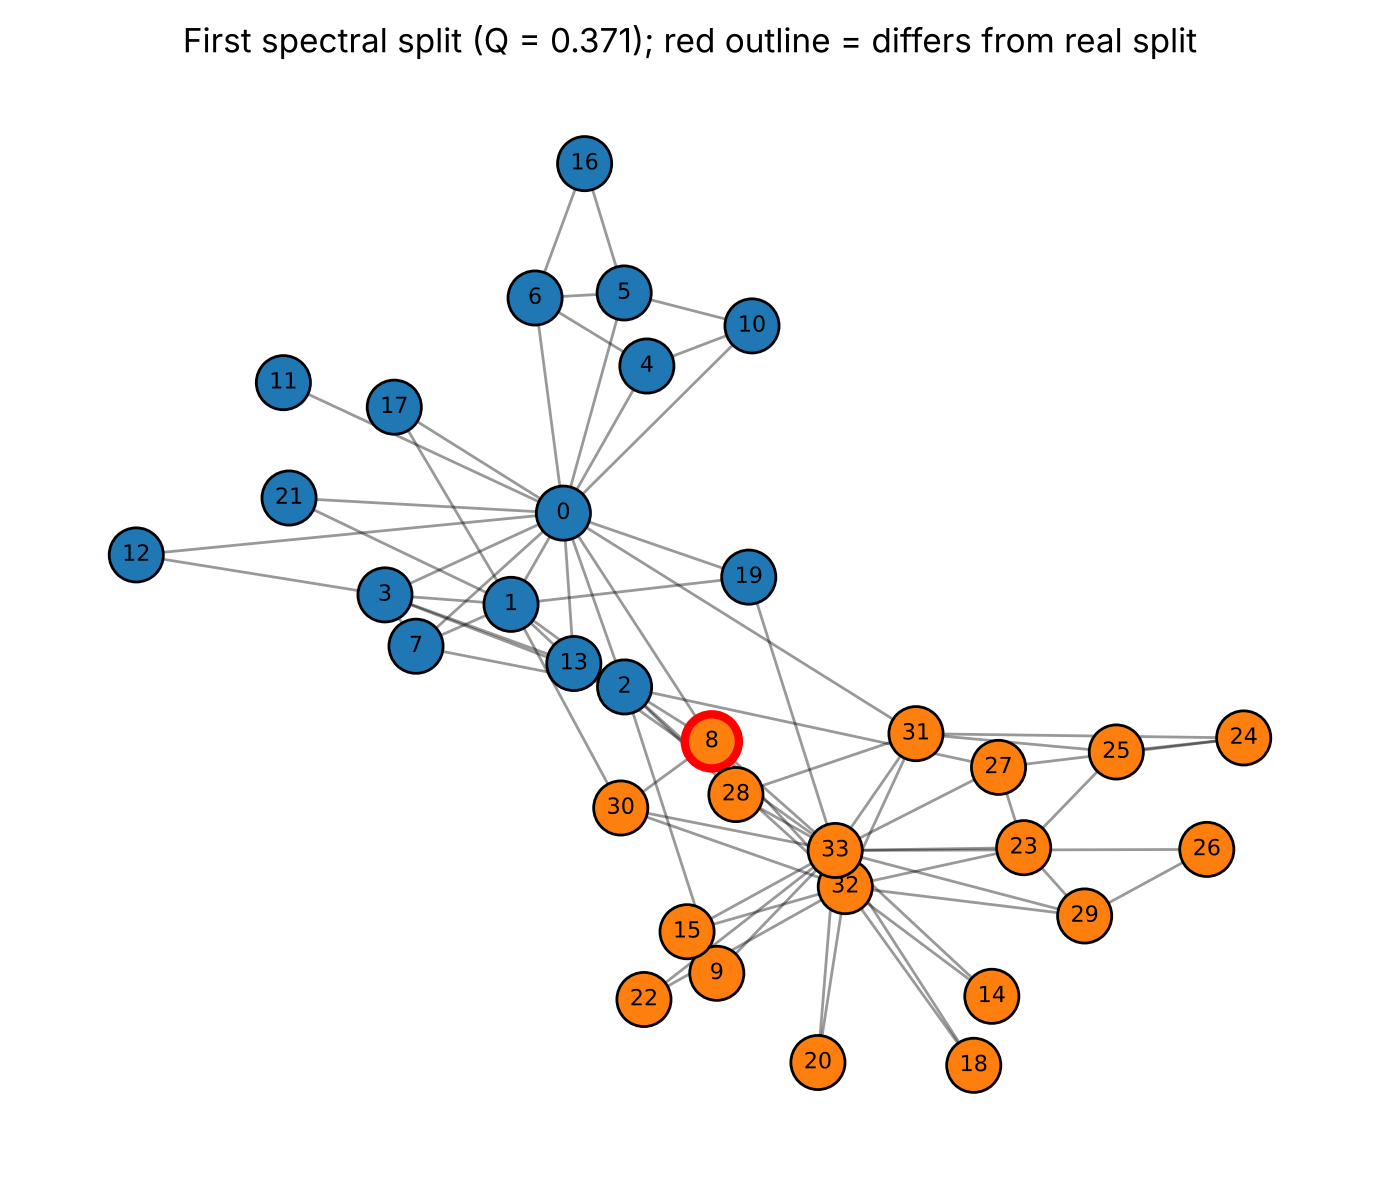

In [ ]:
true_hi = {v for v in G if G.nodes[v]["club"] == "Mr. Hi"}
true_off = set(G.nodes) - true_hi

# label-agnostic comparison
if len(set1 & true_hi) >= len(set2 & true_hi):
    ours_hi, ours_off = set1, set2
else:
    ours_hi, ours_off = set2, set1

mismatch = sorted(ours_hi ^ true_hi)
print("Mr. Hi faction size (true / ours):", len(true_hi), "/", len(ours_hi))
print("misclassified nodes:", mismatch)
print(f"accuracy: {(n - len(mismatch)) / n:.1%}")

# plot: colour = our split, outline = real faction
plt.figure(figsize=(7, 6))
nx.draw_networkx_edges(G, pos, alpha=0.4)
cols = ["tab:blue" if v in ours_hi else "tab:orange" for v in G.nodes]
edge = ["red" if v in mismatch else "black" for v in G.nodes]
nx.draw_networkx_nodes(G, pos, node_color=cols, edgecolors=edge, linewidths=[3 if v in mismatch else 1 for v in G.nodes], node_size=380)
nx.draw_networkx_labels(G, pos, font_size=8)
plt.title(f"First spectral split (Q = {Q_two:.3f}); red outline = differs from real split")
plt.axis("off"); plt.tight_layout()
plt.savefig("assets/01_two_way_split.png", dpi=150)
plt.show()

# 4. Recursive bisection
To split a community `C`, take the block `B(C)` of `B` with rows/columns in `C` and compute its leading eigenpair `(λ₁, u₁)`:
* `λ₁ ≤ 0` → no split of `C` can raise modularity (Theorem 3), so `C` stays whole;
* otherwise → split `C` by the sign of `u₁`.

A tiny tolerance (`1e-10`) replaces exact `0` because of floating-point error. Singletons and splits that leave one side empty are rejected, which guarantees that the loop terminates.

One **iteration** = one round in which *every* community that can still be split is split. `history[t]` stores the list of communities after iteration `t` (`history[0]` is the whole graph).

In [ ]:
def split(nodes, tol=1e-10):
    # Try to bisect one community (list of node ids). Returns (group_a, group_b) or None.
    if len(nodes) <= 1:
        return None
    idx = np.array(nodes)
    B_C = B[np.ix_(idx, idx)]                  # restricted modularity matrix B^(C)
    vals, vecs = np.linalg.eigh(B_C)
    lam, vec = vals[-1], vecs[:, -1]           # leading eigenpair
    if lam <= tol:                             # stopping rule (Theorem 3)
        return None
    s_C = np.where(vec > 0, 1, -1)
    group_a = idx[s_C == 1].tolist()
    group_b = idx[s_C == -1].tolist()
    if len(group_a) == 0 or len(group_b) == 0: # nothing was actually split
        return None
    return sorted(group_a), sorted(group_b)


communities = [list(range(n))]
history = [communities]
while True:
    new_communities, changed = [], False
    for c in communities:
        result = split(c)
        if result is None:
            new_communities.append(c)          # indivisible: keep as it is
        else:
            new_communities.extend(result)
            changed = True
    if not changed:
        break
    communities = new_communities
    history.append(communities)

print("number of iterations (including iteration 0):", len(history))

number of iterations (including iteration 0): 4


## Modularity of each partition
For a partition into communities, `Q = (1/2m) Σ_C Σ_{i,j∈C} B_ij`. This equals `sᵀBs/4m` for two groups: all entries of `B` sum to 0, so `sᵀBs` is twice the same-group sum.

iteration 0: 1 communities, sizes [34], Q = 0.0000
iteration 1: 2 communities, sizes [18, 16], Q = 0.3715
iteration 2: 4 communities, sizes [13, 10, 6, 5], Q = 0.4081
iteration 3: 5 communities, sizes [13, 10, 5, 5, 1], Q = 0.4094


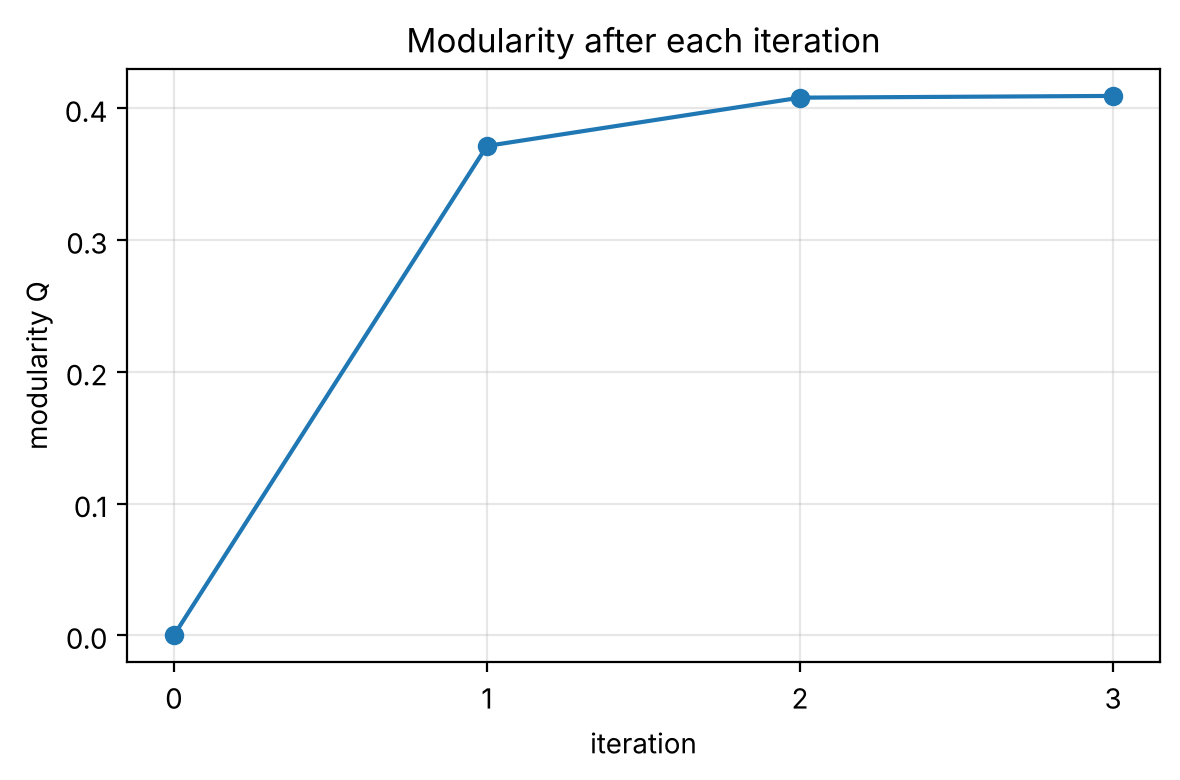

In [ ]:
def Q_of(comms):
    return sum(B[np.ix_(c, c)].sum() for c in comms) / (2 * m)

Q_history = [round(Q_of(c), 12) + 0.0 for c in history]   # +0.0 avoids printing -0.0
for t, comms in enumerate(history):
    sizes = sorted(map(len, comms), reverse=True)
    print(f"iteration {t}: {len(comms)} communities, sizes {sizes}, Q = {Q_history[t]:.4f}")

# sanity: iteration 1 must agree with the s^T B s / 4m value from section 3 (Corollary 1 gives Q = 0 at iteration 0)
assert np.isclose(Q_history[0], 0) and np.isclose(Q_history[1], Q_two)

plt.figure(figsize=(6, 4))
plt.plot(range(len(history)), Q_history, marker="o")
plt.xticks(range(len(history))); plt.xlabel("iteration"); plt.ylabel("modularity Q")
plt.title("Modularity after each iteration"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("assets/02_Q_vs_iteration.png", dpi=150); plt.show()

In [ ]:
print("Final communities:")
for i, c in enumerate(history[-1]):
    print(f"  community {i}: {c}")

Final communities:
  community 0: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  community 1: [11]
  community 2: [4, 5, 6, 10, 16]
  community 3: [24, 25, 27, 28, 31]
  community 4: [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]


# 5. Visualisation after each split
The layout `pos` was computed once, so nodes never move; only the colours change. Each community gets its own colour and every node is labelled with its ID.

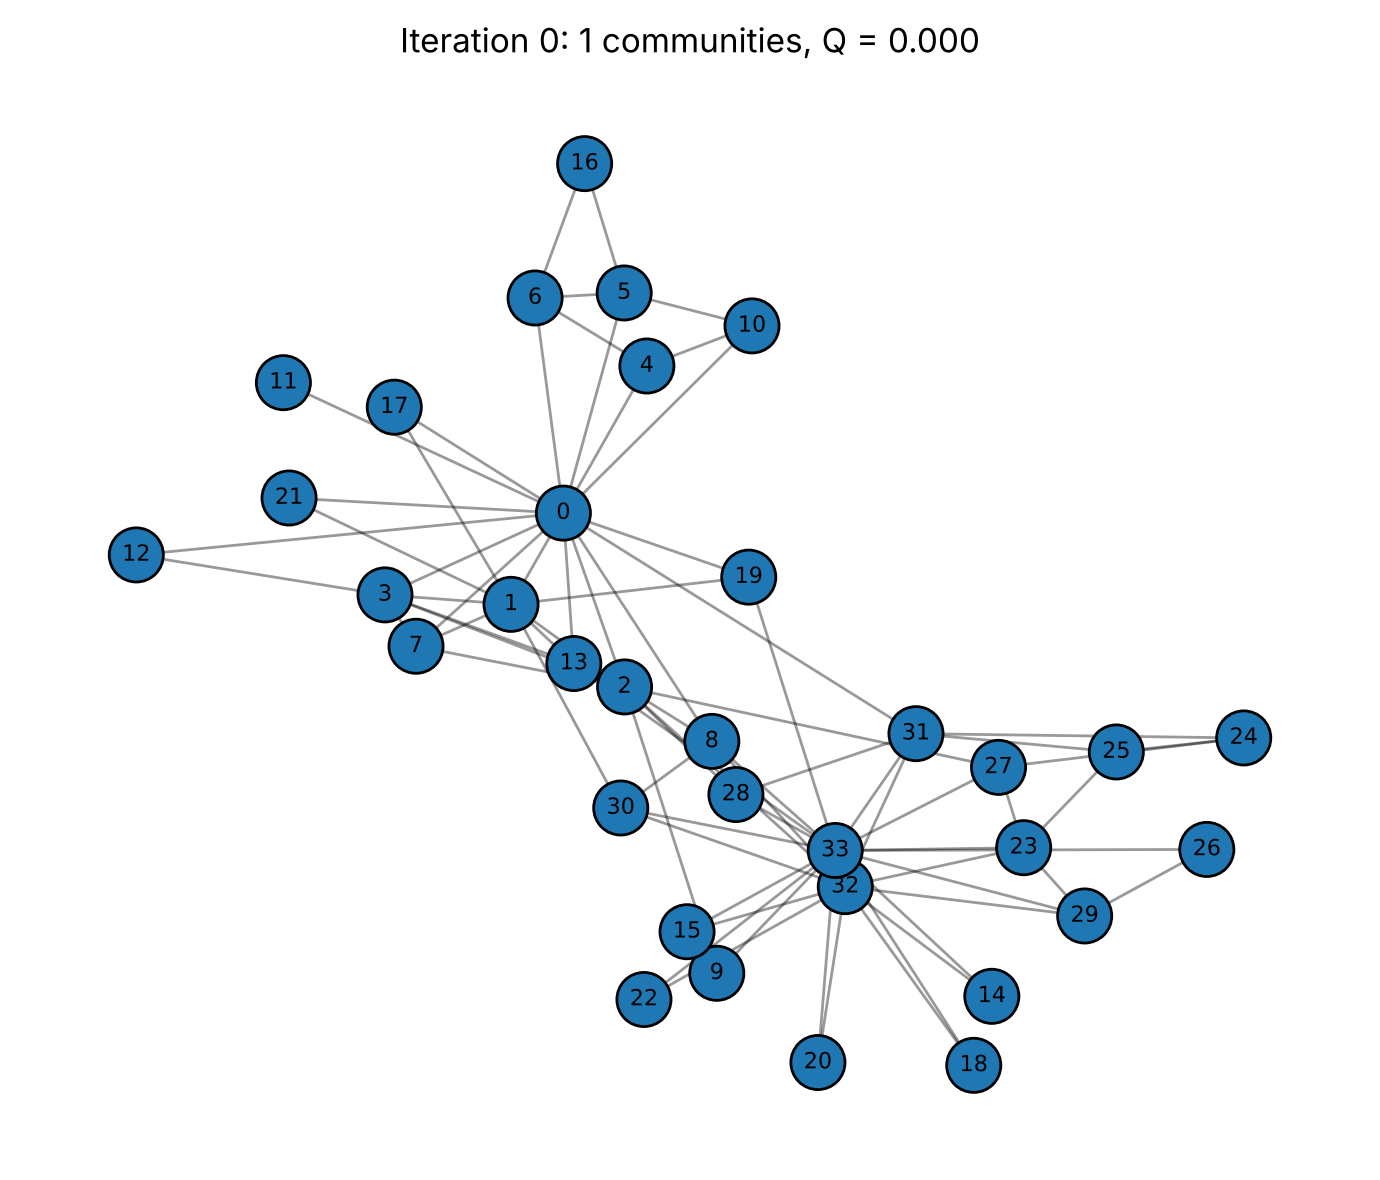

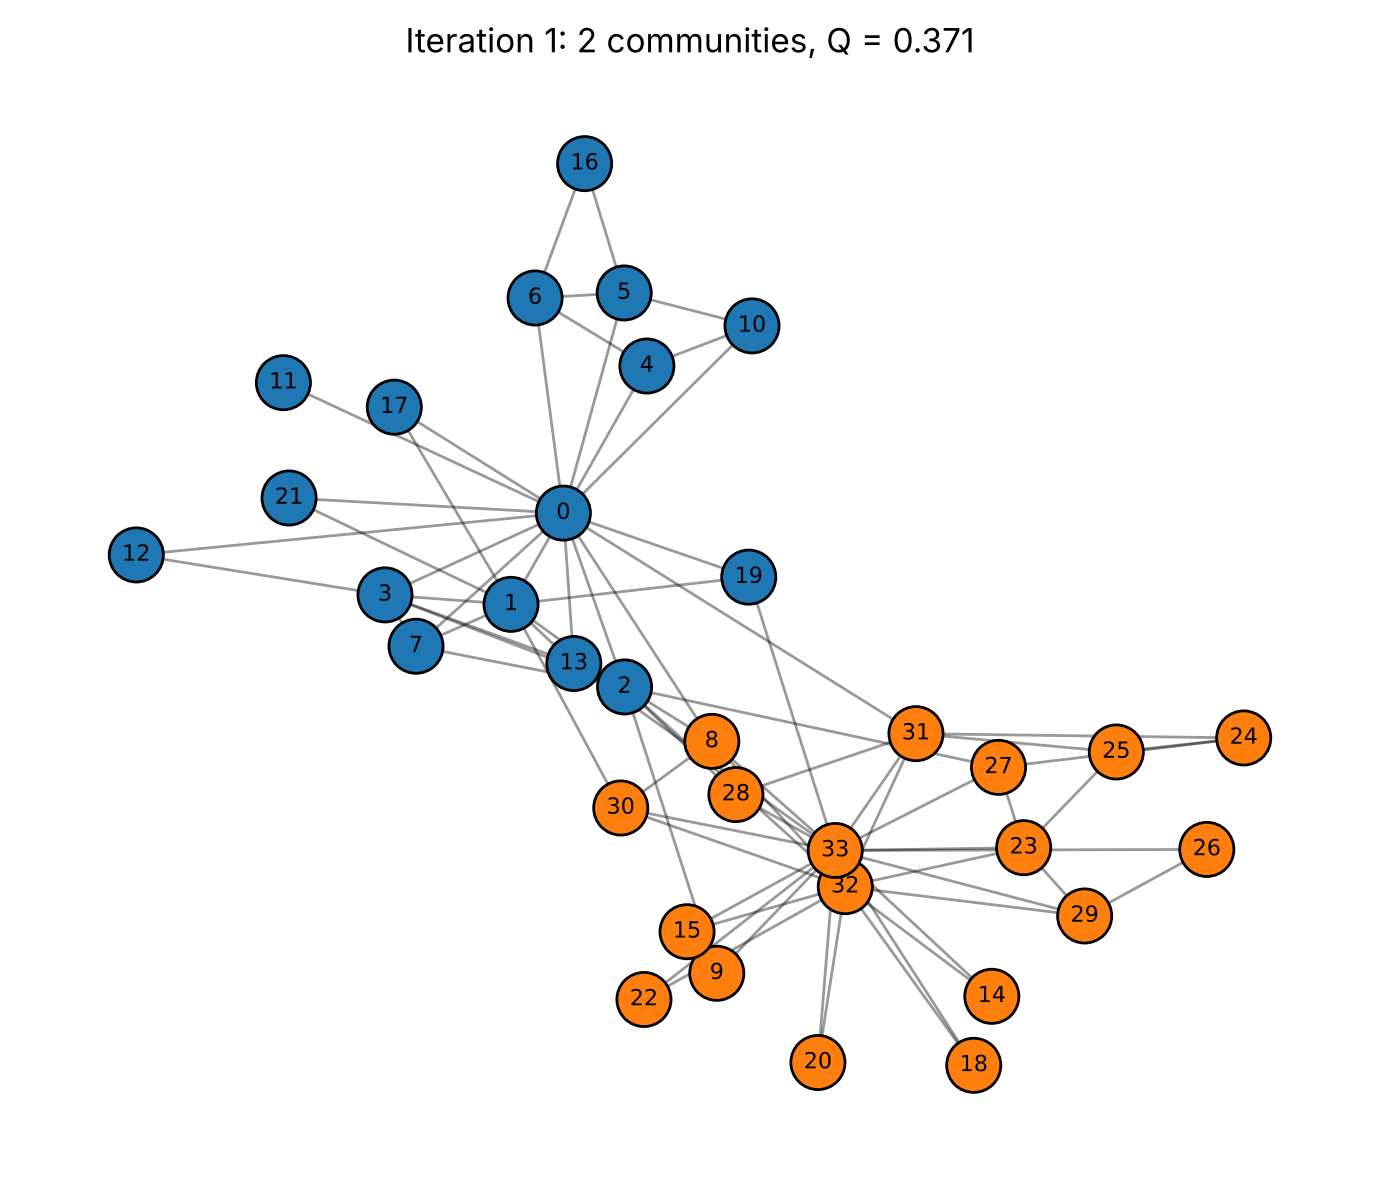

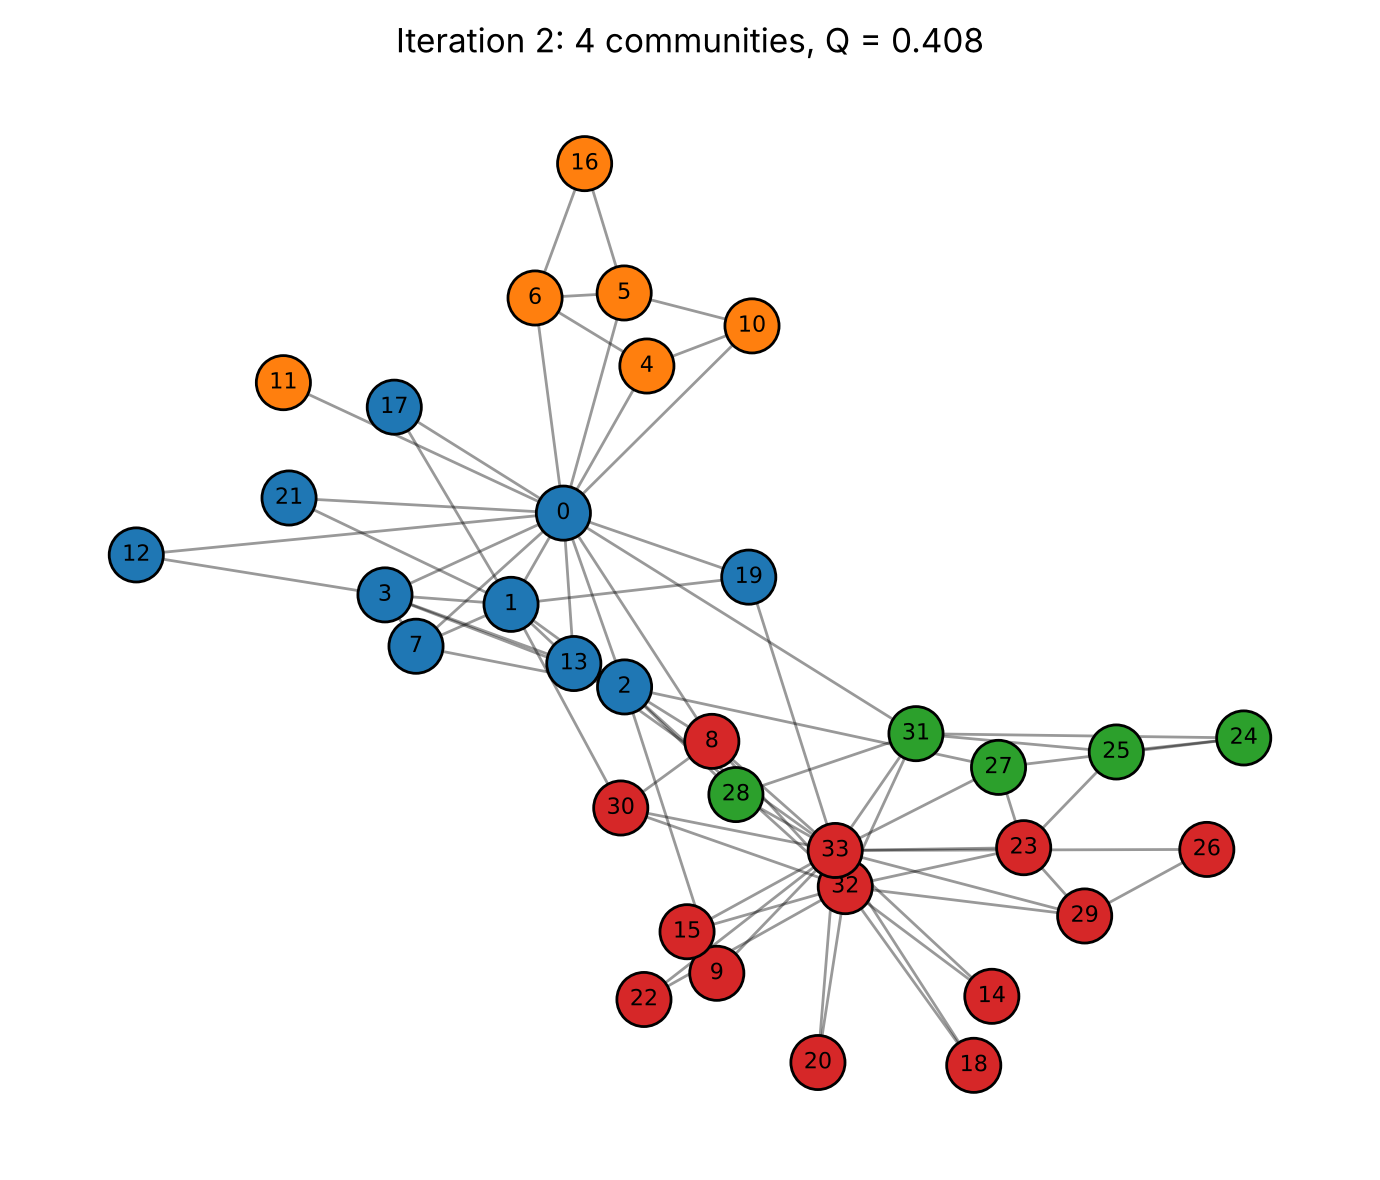

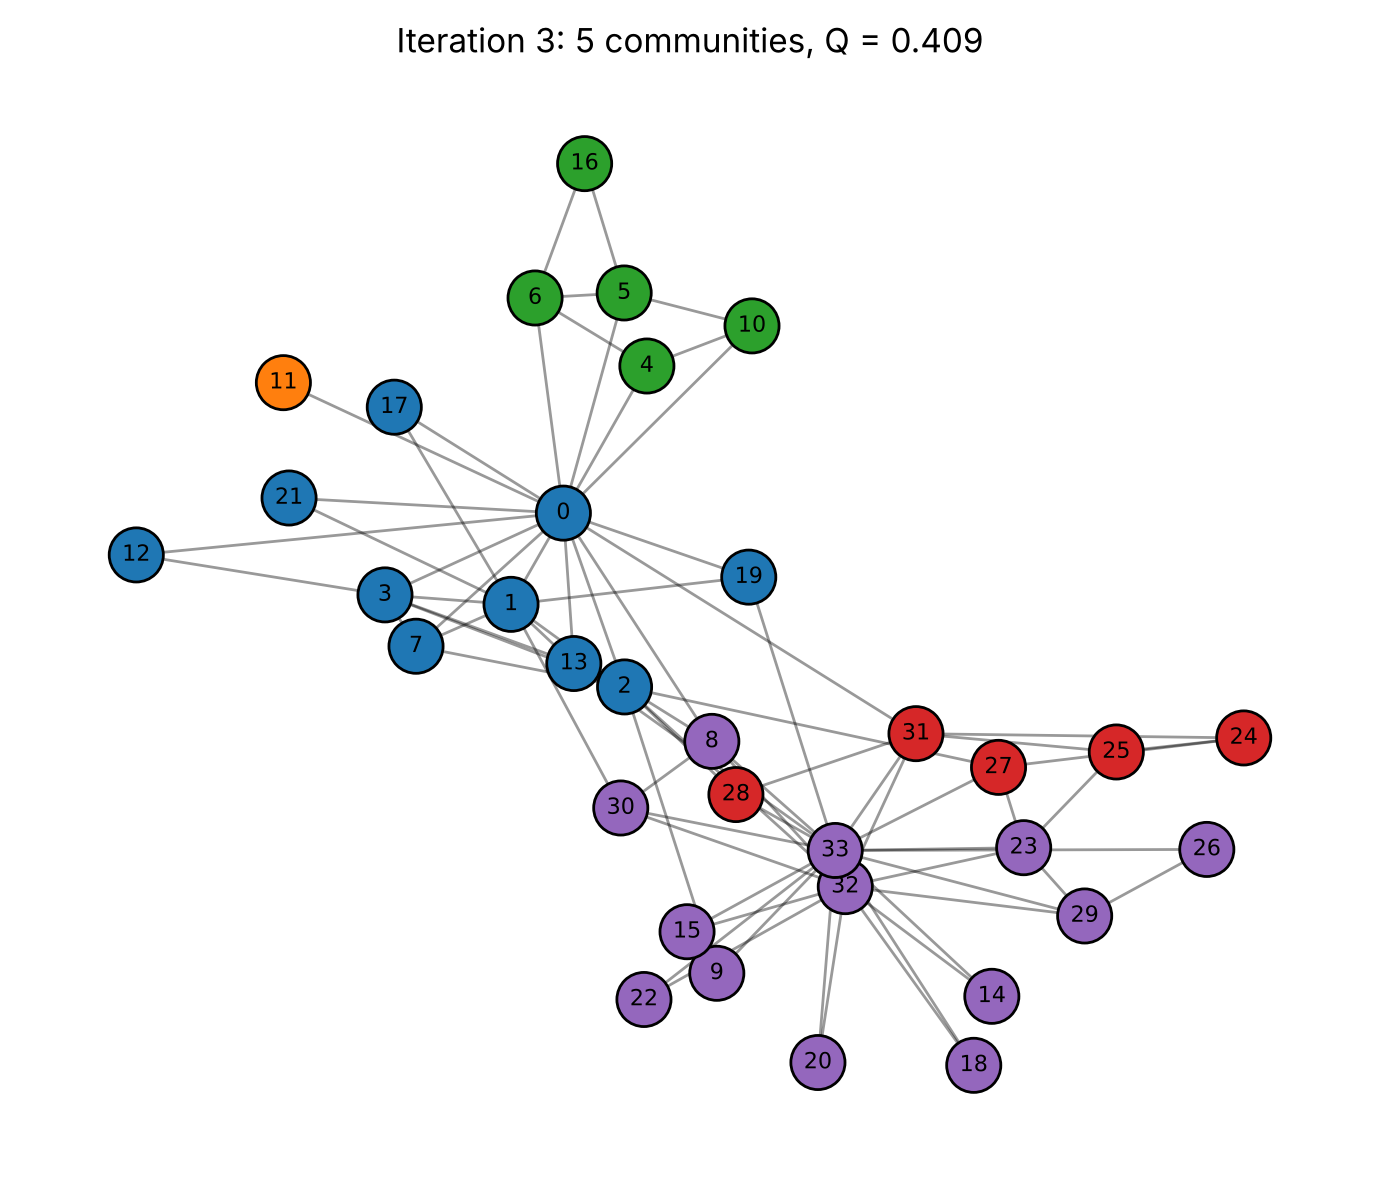

In [ ]:
palette = plt.cm.tab10.colors

for t, comms in enumerate(history):
    color_of = {v: palette[ci % 10] for ci, c in enumerate(comms) for v in c}
    plt.figure(figsize=(7, 6))
    nx.draw_networkx_edges(G, pos, alpha=0.4)
    nx.draw_networkx_nodes(G, pos, node_color=[color_of[v] for v in G.nodes],
                           node_size=380, edgecolors="black")
    nx.draw_networkx_labels(G, pos, font_size=8)
    plt.title(f"Iteration {t}: {len(comms)} communities, Q = {Q_history[t]:.3f}")
    plt.axis("off"); plt.tight_layout()
    plt.savefig(f"assets/03_iteration_{t}.png", dpi=150)
    plt.show()

# 6. Node metrics after each split
After each iteration the four NetworkX metrics are computed for every node:

| Metric | NetworkX function | Meaning |
|---|---|---|
| Degree centrality | `nx.degree_centrality` | fraction of the other nodes a node is directly linked to |
| Betweenness centrality | `nx.betweenness_centrality` | how often a node lies on shortest paths (bridge / broker) |
| Closeness centrality | `nx.closeness_centrality` | inverse of average distance to the others (good "spreader") |
| Clustering coefficient | `nx.clustering` | fraction of a node's neighbours that are also linked |

**Design choice.** Applied to the *whole* graph `G`, these values would never change between iterations. So each metric is computed on the **induced subgraph of the node's own community** (`G.subgraph(c)`). Singleton communities have no defined metrics here and are set to 0. Results are stored in a dictionary `metrics[name][iteration]` → array of length `n`.

In [ ]:
metric_funcs = {
    "degree":      nx.degree_centrality,
    "betweenness": nx.betweenness_centrality,
    "closeness":   nx.closeness_centrality,
    "clustering":  nx.clustering,
}

metrics = {name: {} for name in metric_funcs}      # metrics[name][iteration] -> array (n,)
for t, comms in enumerate(history):
    for name, f in metric_funcs.items():
        vals = np.zeros(n)
        for c in comms:
            if len(c) < 2:                         # singleton: metric undefined -> 0
                continue
            res = f(G.subgraph(c))
            for v in c:
                vals[v] = res[v]
        metrics[name][t] = vals

# Quick look: top-5 nodes per metric at every iteration
for name in metric_funcs:
    print(f"\n{name}")
    for t in range(len(history)):
        top = np.argsort(-metrics[name][t], kind="stable")[:5]
        print(f"  iteration {t}: {top.tolist()}")


degree
  iteration 0: [33, 0, 32, 2, 1]
  iteration 1: [0, 33, 32, 1, 3]
  iteration 2: [0, 33, 1, 32, 24]
  iteration 3: [0, 33, 1, 32, 5]

betweenness
  iteration 0: [0, 33, 32, 2, 31]
  iteration 1: [0, 33, 32, 31, 1]
  iteration 2: [33, 24, 31, 0, 32]
  iteration 3: [33, 24, 31, 0, 32]

closeness
  iteration 0: [0, 2, 33, 31, 8]
  iteration 1: [0, 33, 32, 1, 3]
  iteration 2: [0, 33, 1, 32, 24]
  iteration 3: [0, 33, 1, 32, 5]

clustering
  iteration 0: [7, 12, 14, 15, 16]
  iteration 1: [7, 8, 12, 13, 14]
  iteration 2: [7, 8, 12, 13, 14]
  iteration 3: [7, 8, 12, 13, 14]


# 7. Evolution of the metrics across iterations
One line per node (34 lines) is unreadable, so for each metric the **5 nodes with the highest average value over all iterations** are drawn in colour and labelled; the other 29 nodes are drawn faint in grey so that the overall pattern is still visible.

*Note on clustering:* several nodes (e.g. 7, 12, 14, 15, 20) stay at exactly 1.0 for all iterations, so their lines lie on top of each other and only one colour is visible.

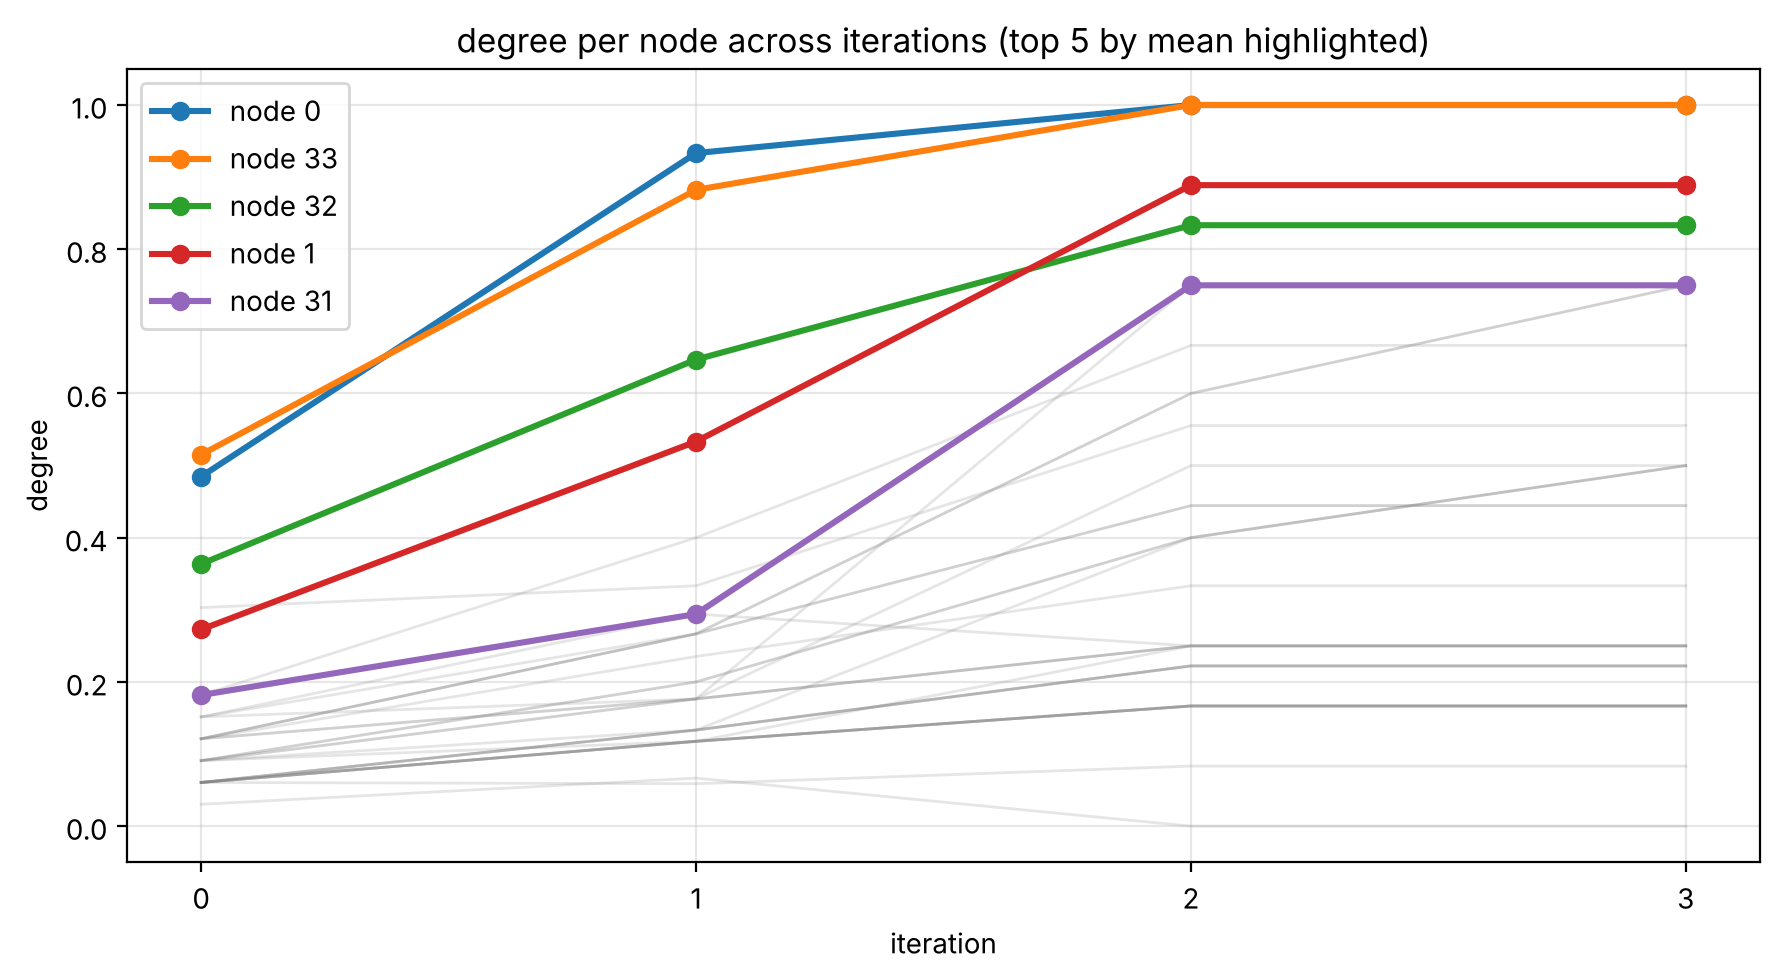

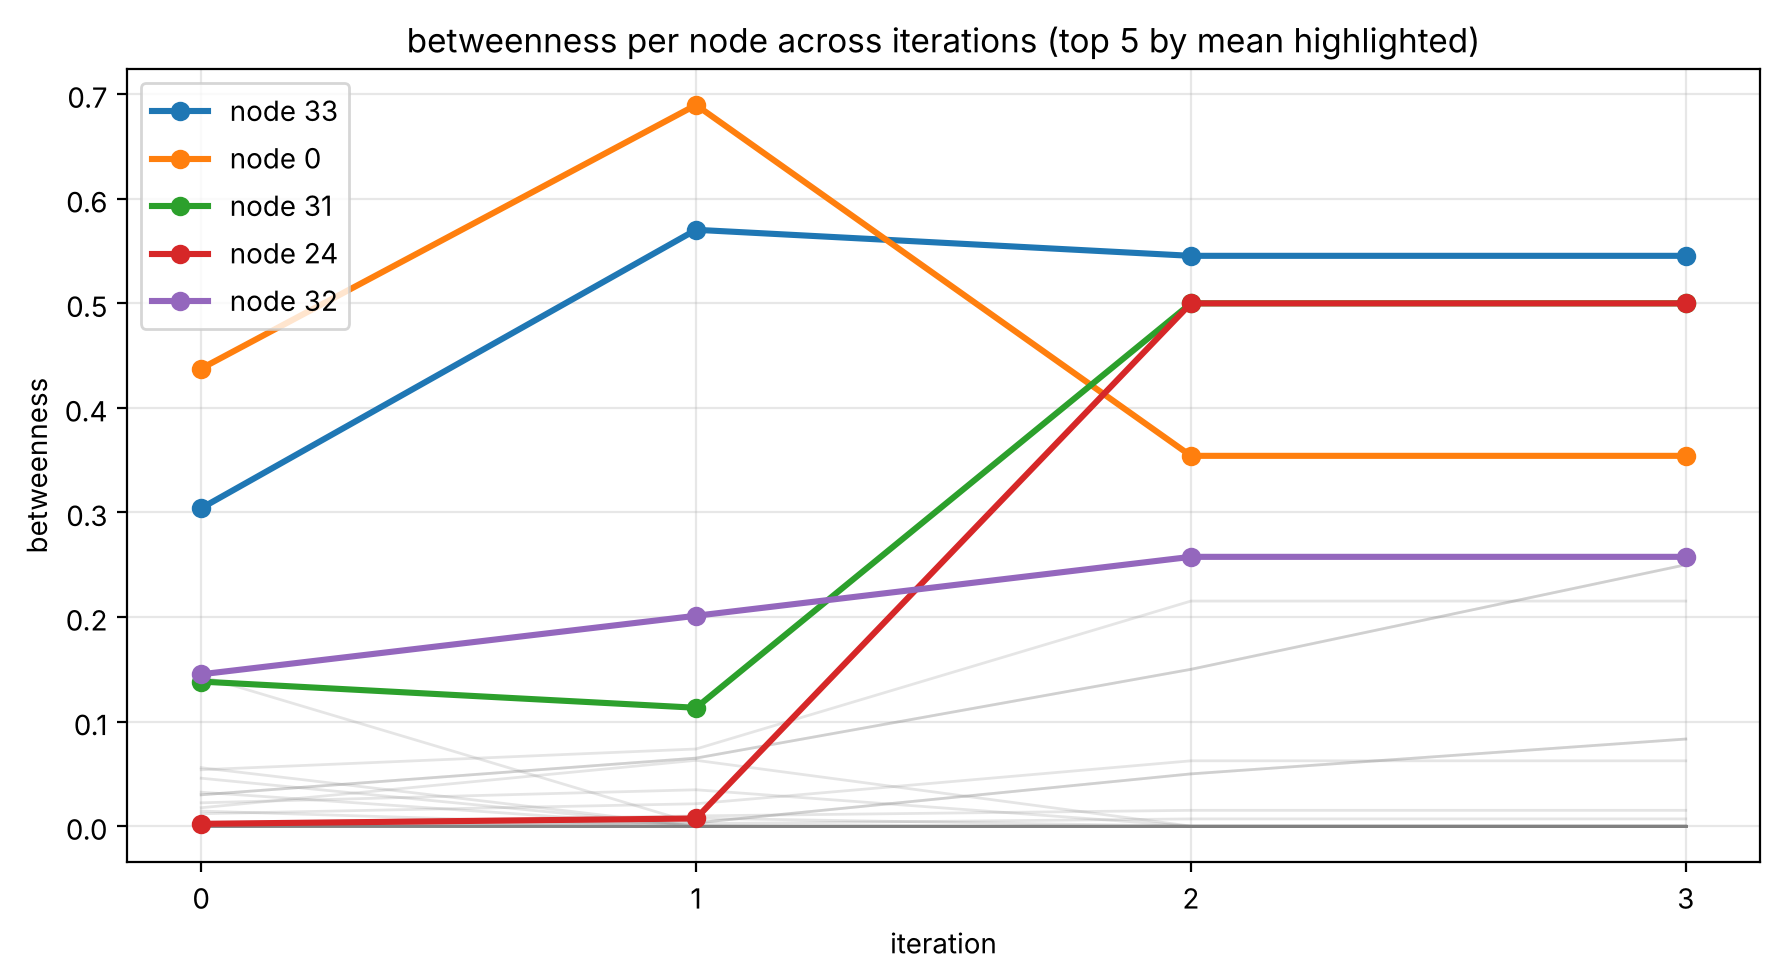

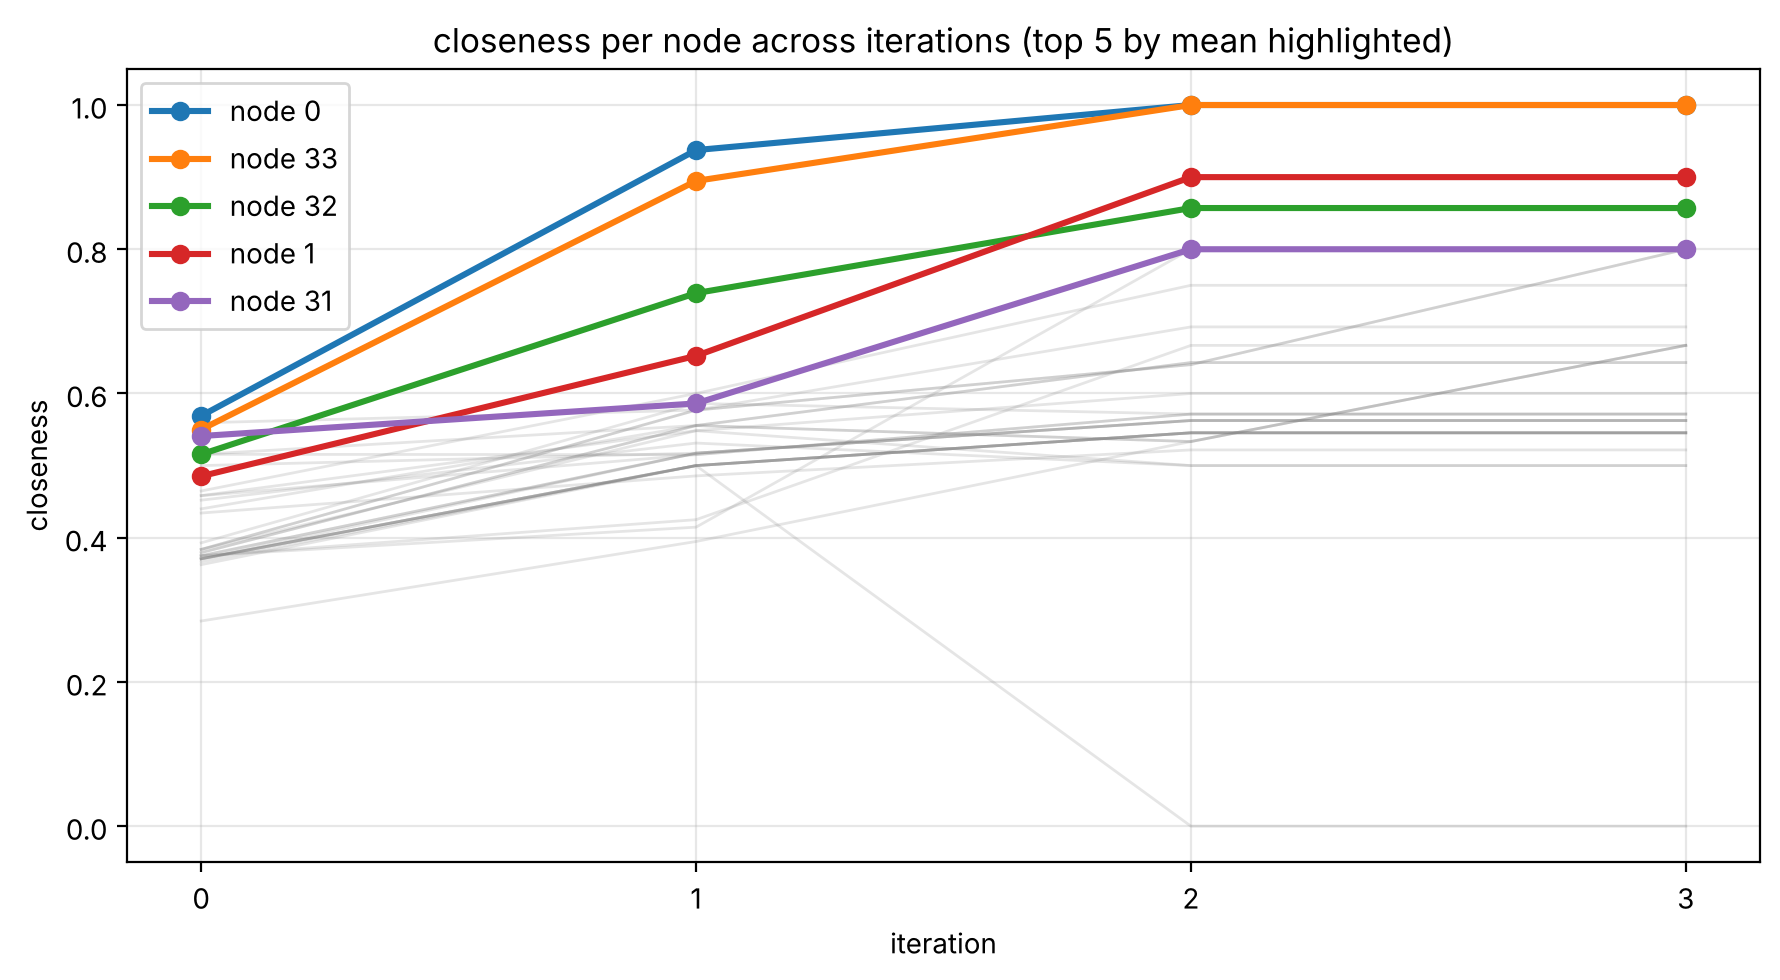

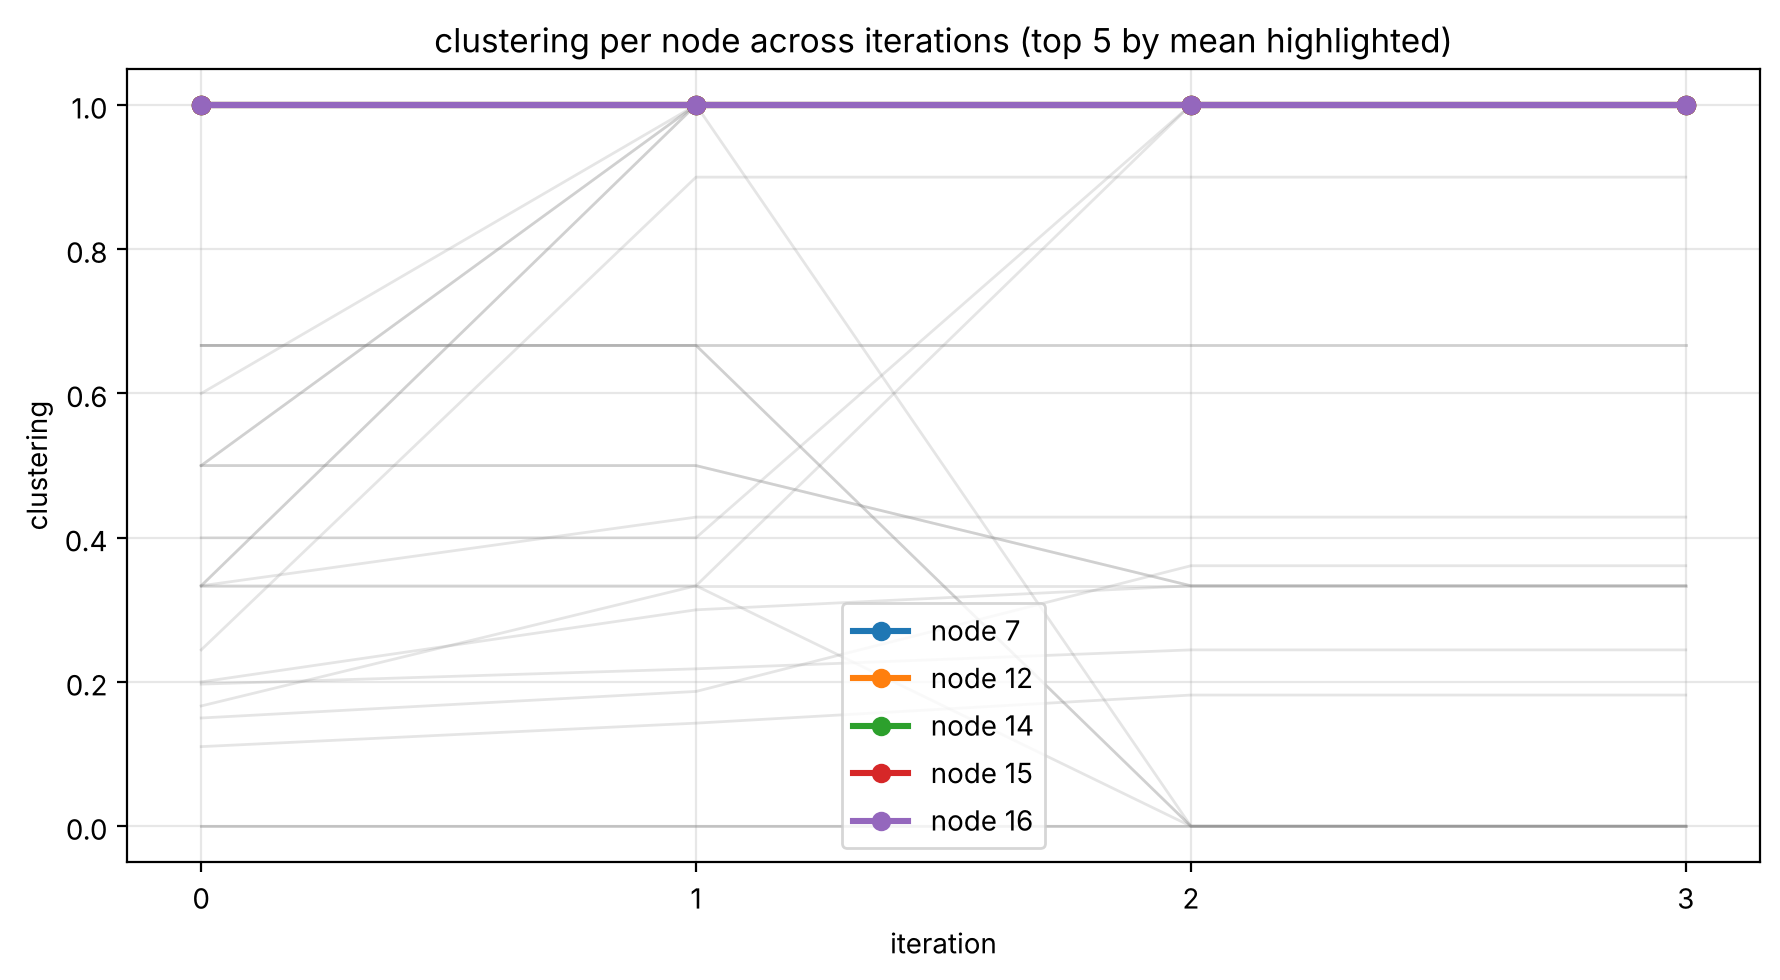

In [ ]:
iters = list(range(len(history)))
colors = plt.cm.tab10.colors

for name in metric_funcs:
    series = np.array([metrics[name][t] for t in iters]).T      # shape (n, iterations)
    top5 = np.argsort(-series.mean(axis=1), kind="stable")[:5]
    plt.figure(figsize=(9, 5))
    for v in range(n):
        if v not in top5:
            plt.plot(iters, series[v], color="gray", alpha=0.2, linewidth=1)
    for rank, v in enumerate(top5):
        plt.plot(iters, series[v], color=colors[rank], marker="o", linewidth=2.2, label=f"node {v}")
    plt.title(f"{name} per node across iterations (top 5 by mean highlighted)")
    plt.xlabel("iteration"); plt.ylabel(name); plt.xticks(iters)
    plt.grid(alpha=0.3); plt.legend()
    plt.tight_layout()
    plt.savefig(f"assets/04_{name}_evolution.png", dpi=150)
    plt.show()

### Which nodes stay central?
For each of the three centrality measures, the nodes that are in the top 5 at **every** iteration are listed (clustering measures cohesion, not centrality, so it is left out).

In [ ]:
for name in ["degree", "betweenness", "closeness"]:
    tops = [set(np.argsort(-metrics[name][t], kind="stable")[:5].tolist()) for t in iters]
    print(f"{name:12s} top-5 at every iteration:", sorted(set.intersection(*tops)))

print("\nValues of nodes 0 and 33 (the two leaders) per iteration:")
for name in metric_funcs:
    print(f"  {name:12s} node 0 :", np.round([metrics[name][t][0] for t in iters], 3),
          "| node 33:", np.round([metrics[name][t][33] for t in iters], 3))

degree       top-5 at every iteration: [0, 1, 32, 33]
betweenness  top-5 at every iteration: [0, 31, 32, 33]
closeness    top-5 at every iteration: [0, 33]

Values of nodes 0 and 33 (the two leaders) per iteration:
  degree       node 0 : [0.485 0.933 1.    1.   ] | node 33: [0.515 0.882 1.    1.   ]
  betweenness  node 0 : [0.438 0.69  0.354 0.354] | node 33: [0.304 0.57  0.545 0.545]
  closeness    node 0 : [0.569 0.938 1.    1.   ] | node 33: [0.55  0.895 1.    1.   ]
  clustering   node 0 : [0.15  0.187 0.361 0.361] | node 33: [0.11  0.143 0.182 0.182]


# 8. Discussion
**Result of the splitting.** The method starts with the whole club (Q = 0, as Corollary 1 predicts) and stops after three rounds with 5 communities of sizes 13, 10, 5, 5 and 1. The first split gives groups of 16 and 18 nodes with Q = 0.371 and matches the real fission of the club for 33 of 34 members (97.1%); the only misclassified member is node 8. Q then rises to 0.408 and 0.409 and flattens, because after round 3 every community has a leading eigenvalue ≤ 0 (Theorem 3). Following the handout, the plain block of `B` is used for each community, which is probably why the last split isolates node 11, whose only neighbour (node 0) lies in a different community, so inside its group it is linked less than chance to everyone (a very small gain in Q).

**Which nodes stay central?** Nodes 0 and 33 (the instructor "Mr. Hi" and the administrator) are in the top 5 for degree, betweenness and closeness at every iteration, and they are the only two nodes that are in the top 5 for closeness at every iteration. Nodes 32 and 31 also stay in the top 5 for betweenness, and node 1 and node 32 for degree. Node 33 ends with the highest betweenness (0.545); node 0's betweenness first rises (0.44 → 0.69, because inside its half of the club it connects most members) and then falls to 0.35 when its community is divided further.

**How community structure influences the metrics.** Metrics were computed on each community's induced subgraph, so they change with every split.
* *Degree and closeness* are normalised by the size of the (sub)graph, so they jump when a node is measured inside a smaller community (node 0's degree centrality goes 0.49 → 0.93 → 1.0). The raw values therefore matter less than the rankings across iterations.
* *Betweenness* of bridge nodes collapses once the edges between communities are removed: node 2 drops from 0.144 to 0.002 after the first split. Conversely, nodes that sit between sub-communities inside a group gain (nodes 24 and 31 go to 0.5 inside their 5-node community).
* *Clustering* rises for nodes whose neighbours are all in the same community (node 8: 0.5 → 1.0, node 2: 0.24 → 0.90; the mean clustering goes 0.57 → 0.68). Eleven nodes (7, 12, 14, 15, 16, 17, 18, 20, 21, 22, 26) stay at exactly 1.0 throughout, since splitting never cuts their triangles.

**Conclusion.** Recursive spectral bisection recovers the real two-faction split almost exactly (all but node 8) and then refines it into smaller communities, with Q ≈ 0.41 when no community has a positive leading eigenvalue. Nodes 0 and 33 remain the most central throughout, but what the metrics mean changes with the split: on the whole graph they describe a node's global position, inside a community they describe its local role.


# References
* Newman, M. E. J. (2006). Modularity and community structure in networks. *PNAS*, 103(23), 8577–8582.
* Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, 33(4), 452–473.
* Hagberg, A., Schult, D., Swart, P. (2008). Exploring network structure, dynamics, and function using NetworkX. *Proc. SciPy 2008*.